### Diversity, Sovereignty and Vulnerability in Brazilian DNS Infrastructure

Provider Concentration and Sectoral Dependence
Which are the most dominant DNS providers in the dataset?
- Gráfico: Pareto chart (top providers)

What is the market share of major providers per sector?
- Gráfico: heatmap (sector × provider)
- Are there sectors that are overly dependent on one or two providers?


In [1]:
import pandas as pd
import os
import seaborn as sns

BASE_DATA = r"..\src\br_analysis_data.csv"
base_data = pd.read_csv(BASE_DATA, sep=';', encoding='utf-8')
display(base_data.sort_values(by='revenue', ascending=False).head(5))

base_data['dominant_provider'] = base_data['dominant_provider'].replace('Colt Technology Services', 'Colt')

print(base_data.dtypes)

PLOT_FONT_SIZE = 12


,company_name,country_name,state_name,city_name,sector_primary,revenue,earnings,total_assets,domain,num_ns,...,dominant_provider_country,dominant_provider_asn,only_one_provider,distinct_asns,distinct_countries,country_list,provider_list,num_ns_in_brazil,num_ns_foreign,infra_type
718,petrobras,Brazil,RJ,RIO DE JANEIRO,Oil and Chemical,511944000.0,511944000.0,1.050888e+09,petrobras.com.br,4,...,US,16509,True,1,1,['US'],['Amazon'],0,4,100% estrangeira
545,jbs,Brazil,SP,SAO PAULO,Food and Beverages,363816537.0,363816537.0,2.061321e+08,jbs.com.br,4,...,US,8075,True,1,1,['US'],['Microsoft'],0,4,100% estrangeira
108,banco do brasil,Brazil,DF,BRASILIA,Financial Sector,269225339.0,269225339.0,2.172480e+09,bb.com.br,4,...,BR,11993,True,1,1,['BR'],['Banco do Brasil'],8,0,100% nacional
761,raizen combustiveis,Brazil,RJ,RIO DE JANEIRO,Energy,245831790.0,245831790.0,1.115515e+08,raizen.com.br,4,...,US,8075,True,1,1,['US'],['Microsoft'],0,20,100% estrangeira
528,itau unibanco holding,Brazil,SP,SAO PAULO,Financial Sector,222385000.0,222385000.0,2.543100e+09,itau.com.br,8,...,NL,21342,True,1,2,"['NL', 'US']",['Akamai'],0,112,100% estrangeira


company_name                  object
country_name                  object
state_name                    object
city_name                     object
sector_primary                object
revenue                      float64
earnings                     float64
total_assets                 float64
domain                        object
num_ns                         int64
num_asn                        int64
asn_list                      object
num_country                    int64
countries_used                object
pct_national_ns              float64
only_foreign_ns                 bool
has_ipv4_ns                     bool
has_ipv6_ns                     bool
dual_stack                      bool
dominant_provider             object
dominant_provider_country     object
dominant_provider_asn         object
only_one_provider               bool
distinct_asns                  int64
distinct_countries             int64
country_list                  object
provider_list                 object
n

### Provider Concentration and Sectoral Dependence
#### Which are the most dominant DNS providers in the dataset?
→ Gráfico: Pareto chart (top providers)
#### What is the market share of major providers per sector?
→ Gráfico: heatmap (sector × provider)
#### Are there sectors that are overly dependent on one or two providers?
→ Gráfico: stacked bar chart

In [2]:
import pandas as pd

# Número de domínios por setor
domains_by_sector = base_data.groupby('sector_primary').size().reset_index(name='Domain_Count')

# Receita total por setor
revenue_by_sector = base_data.groupby('sector_primary')['revenue'].sum().reset_index(name='Total_Revenue')

# Junta as duas informações
sector_summary = pd.merge(domains_by_sector, revenue_by_sector, on='sector_primary')

# Ordena pelo número de domínios (Domain_Count) em ordem decrescente
sector_summary = sector_summary.sort_values(by='Domain_Count', ascending=False).reset_index(drop=True)

# Converte a receita total para milhões de reais
sector_summary['Total_Revenue'] = (sector_summary['Total_Revenue'] / 1_000).round(1)

sector_summary = sector_summary.rename(columns={
    'sector_primary': 'Primary Sector',
    'Domain_Count': 'Main Domain Count',
    'Total_Revenue': 'Total Revenue in Millions (R$)'
})

# Salva em CSV
sector_summary.to_csv('./tables/br_sector_domain_and_revenue_summary.csv', sep=';', index=False, encoding='utf-8')

display(sector_summary)

# Sugestão de título para a tabela resumo setor
print("Resumo de domínios e receita total por setor primário no Brasil")

,Primary Sector,Main Domain Count,Total Revenue in Millions (R$)
0,Financial Sector,205,1906038.7
1,Energy,111,1599770.6
2,Transport Logistics and Logistic Services,95,384381.0
3,Health and Healthcare Services,85,451890.4
4,Agribusiness,76,626724.3
5,Technology and Telecommunications,71,195326.7
6,Wholesale and Retail,64,481577.9
7,Capital Goods and Industrial Equipment,57,267284.4
8,Real Estate and Construction,54,99666.4
9,Food and Beverages,49,859565.3


Resumo de domínios e receita total por setor primário no Brasil


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



import matplotlib.pyplot as plt
import seaborn as sns

# top providers by concentrated count
top_providers = base_data['dominant_provider'].value_counts().head(10)
top_providers = top_providers.sort_values(ascending=False)
top_providers = top_providers.reset_index()
top_providers.columns = ['dominant_provider', 'count']

# Save top providers by count to CSV
top_providers.to_csv('./tables/br_top_dns_providers_by_count.csv', sep=';', encoding='utf-8', index=False)


# top providers by concentrated revenue
top_providers_revenue = base_data.groupby('dominant_provider')['revenue'].sum().reset_index()
top_providers_revenue = top_providers_revenue.sort_values(by='revenue', ascending=False).head(10)
top_providers_revenue['revenue'] = top_providers_revenue['revenue'] / 1_000  # Convert to millions

# Save top providers by revenue to CSV
top_providers_revenue.to_csv('./tables/br_top_dns_providers_by_revenue.csv', sep=';', encoding='utf-8', index=False)



# Parâmetros do padrão
square_size = 5     # lado do quadrado em polegadas
hspace = 0.1        # espaço horizontal entre gráficos
n_plots = 2
fig_width = n_plots * square_size 
fig_height = square_size

# Carregar dados dos top 10 providers já salvos
top_providers = pd.read_csv('./tables/br_top_dns_providers_by_count.csv', sep=';')
top_providers_revenue = pd.read_csv('./tables/br_top_dns_providers_by_revenue.csv', sep=';')

# # --------- Figura ---------
# fig, axes = plt.subplots(1, n_plots, figsize=(fig_width, fig_height), sharey=False)
# if n_plots == 1:
#     axes = [axes]  # Garante iterabilidade

# # Barplot: Top DNS Providers by Count
# sns.barplot(
#     data=top_providers,
#     x='dominant_provider',
#     y='count',
#     palette='tab10',
#     ax=axes[0]
# )
# axes[0].set_title('a)', fontsize=14)
# axes[0].set_ylabel('Count')
# axes[0].set_xlabel('')
# axes[0].tick_params(axis='x', rotation=90)
# axes[0].set_box_aspect(1)

# # Barplot: Top DNS Providers by Revenue
# sns.barplot(
#     data=top_providers_revenue,
#     x='dominant_provider',
#     y='revenue',
#     palette='tab10',
#     ax=axes[1]
# )
# axes[1].set_title('b)', fontsize=14)
# axes[1].set_ylabel('Revenue in Millions (R$)')
# axes[1].set_xlabel('')
# axes[1].tick_params(axis='x', rotation=90)
# axes[1].set_box_aspect(1)

# fig.supxlabel('DNS Provider', fontsize=13)
# plt.subplots_adjust(left=0.07, right=0.99, top=0.92, bottom=0.18, wspace=hspace/square_size)
# plt.show()

# #fig.savefig(r'.\graphs\pareto_top10_dns_providers_side_by_side.png', dpi=300, bbox_inches='tight')


C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_33132\918828085.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_33132\918828085.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_33132\918828085.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_33132\918828085.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign th

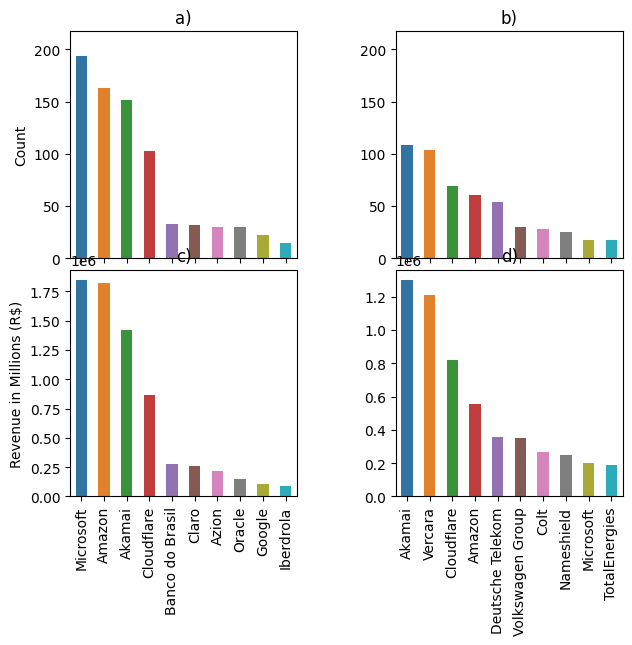

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Padrão ABNT
textwidth_cm = 16
textwidth_inch = textwidth_cm / 2.54  # ≈ 6.3 polegadas
font_size = 10

n_rows = 2
n_cols = 2

# Tamanho de cada gráfico
square_size = 2 #textwidth_inch / n_cols  # cada quadrado ocupa metade da largura
hspace = 0.70     # espaço horizontal entre gráficos em polegadas
vspace = 0.10    # espaço vertical entre gráficos em polegadas

fig_width = textwidth_inch
fig_height = 3+ n_rows * square_size + (n_rows - 10) * vspace

# Carregar dados
br_count = pd.read_csv('./tables/br_top_dns_providers_by_count.csv', sep=';')
br_revenue = pd.read_csv('./tables/br_top_dns_providers_by_revenue.csv', sep=';')
eu_count = pd.read_csv('./tables/eu_top_dns_providers_by_count.csv', sep=';')
eu_revenue = pd.read_csv('./tables/eu_top_dns_providers_by_revenue.csv', sep=';')

# Escala igual nos gráficos
ymax_count = max(br_count['count'].max(), eu_count['count'].max()) * 1.12
ymax_revenue = max(br_revenue['revenue'].max(), eu_revenue['revenue'].max()) * 1.12

# ---- Figura 2x2 ----
fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), sharex=False)
axes = axes.flatten()

bar_kwargs = dict(width=0.5)

# a) BR Count
sns.barplot(
    data=br_count,
    x='dominant_provider',
    y='count',
    palette='tab10',
    ax=axes[0],
    **bar_kwargs
)
axes[0].set_title('a)', fontsize=font_size+2, pad=6)
axes[0].set_ylabel('Count', fontsize=font_size)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=90, labelsize=font_size)
axes[0].tick_params(axis='y', labelsize=font_size)
axes[0].set_box_aspect(1)
axes[0].set_ylim(0, ymax_count)

# b) EU Count
sns.barplot(
    data=eu_count,
    x='dominant_provider',
    y='count',
    palette='tab10',
    ax=axes[1],
    **bar_kwargs
)
axes[1].set_title('b)', fontsize=font_size+2, pad=6)
axes[1].set_ylabel('')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=90, labelsize=font_size)
axes[1].tick_params(axis='y', labelsize=font_size)
axes[1].set_box_aspect(1)
axes[1].set_ylim(0, ymax_count)

# c) BR Revenue
sns.barplot(
    data=br_revenue,
    x='dominant_provider',
    y='revenue',
    palette='tab10',
    ax=axes[2],
    **bar_kwargs
)
axes[2].set_title('c)', fontsize=font_size+2, pad=6)
axes[2].set_ylabel('Revenue in Millions (R$)', fontsize=font_size)
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=90, labelsize=font_size)
axes[2].tick_params(axis='y', labelsize=font_size)
axes[2].set_box_aspect(1)

# d) EU Revenue
sns.barplot(
    data=eu_revenue,
    x='dominant_provider',
    y='revenue',
    palette='tab10',
    ax=axes[3],
    **bar_kwargs
)
axes[3].set_title('d)', fontsize=font_size+2, pad=6)
axes[3].set_ylabel('')
axes[3].set_xlabel('')
axes[3].tick_params(axis='x', rotation=90, labelsize=font_size)
axes[3].tick_params(axis='y', labelsize=font_size)
axes[3].set_box_aspect(1)

plt.subplots_adjust(
    left=0.08, right=0.98,
    top=0.93, bottom=0.18,
    wspace=hspace/square_size,
    hspace=vspace/square_size
)

plt.show()
fig.savefig(r'.\graphs\pareto_top10_dns_providers_br_vs_eu.png', dpi=300, bbox_inches='tight')


In [ ]:
# Herfindahl-Hirschman Index

import pandas as pd

# Supondo que base_data já está carregado e tem as colunas 'dominant_provider', 'sector_primary' e 'revenue'

# Calcule a receita total por setor
total_revenue_by_sector = base_data.groupby('sector_primary')['revenue'].sum()

# Calcule a receita por provedor e setor
provider_sector_revenue = base_data.groupby(['dominant_provider', 'sector_primary'])['revenue'].sum().reset_index()

# Calcule o marketshare (em %) de cada provedor em cada setor
provider_sector_revenue['marketshare'] = provider_sector_revenue.apply(
    lambda row: (row['revenue'] / total_revenue_by_sector[row['sector_primary']]) * 100
    if total_revenue_by_sector[row['sector_primary']] > 0 else 0,
    axis=1
)

# Crie o DataFrame pivô: linhas = provedores, colunas = setores, valores = marketshare
marketshare_df = provider_sector_revenue.pivot_table(
    index='dominant_provider',
    columns='sector_primary',
    values='marketshare',
    fill_value=0
)
# Opcional: arredonde para 2 casas decimais
marketshare_df = marketshare_df.round(2)

# Exiba o resultado
display(marketshare_df)

# Calcule o HHI para cada setor (coluna)
hhi_by_sector = (marketshare_df ** 2).sum(axis=0)

display(hhi_by_sector)

# Opcional: converta para DataFrame para facilitar o plot
hhi_df = hhi_by_sector.reset_index()
hhi_df.columns = ['Sector', 'HHI']

# Salve o DataFrame de marketshare por provedor e setor em CSV
hhi_df.to_csv('./tables/br_provider_sector_marketshare_by_revenue.csv', sep=';', encoding='utf-8')



# Calcule o total de empresas por setor
total_count_by_sector = base_data.groupby('sector_primary').size()

# Calcule o número de empresas por provedor e setor
provider_sector_count = base_data.groupby(['dominant_provider', 'sector_primary']).size().reset_index(name='count')

# Calcule o marketshare (em %) de cada provedor em cada setor (por quantidade)
provider_sector_count['marketshare'] = provider_sector_count.apply(
    lambda row: (row['count'] / total_count_by_sector[row['sector_primary']]) * 100
    if total_count_by_sector[row['sector_primary']] > 0 else 0,
    axis=1
)

# Crie o DataFrame pivô: linhas = provedores, colunas = setores, valores = marketshare (por quantidade)
marketshare_count_df = provider_sector_count.pivot_table(
    index='dominant_provider',
    columns='sector_primary',
    values='marketshare',
    fill_value=0
)
marketshare_count_df = marketshare_count_df.round(2)

display(marketshare_count_df)

# Calcule o HHI para cada setor (coluna) usando marketshare por quantidade
hhi_count_by_sector = (marketshare_count_df ** 2).sum(axis=0)

display(hhi_count_by_sector)

# Opcional: converta para DataFrame para facilitar o plot
hhi_count_df = hhi_count_by_sector.reset_index()
hhi_count_df.columns = ['Sector', 'HHI_Count']

# Salve o DataFrame de marketshare por provedor e setor em CSV (por quantidade)
hhi_count_df.to_csv('./tables/br_provider_sector_marketshare_by_count.csv', sep=';', encoding='utf-8')



# Combine as duas métricas HHI em uma única tabela
hhi_merged = pd.merge(
    hhi_count_df,
    hhi_df,
    on='Sector',
    how='outer',
    suffixes=('_count', '_revenue')
)
hhi_merged = hhi_merged.rename(columns={
    'Sector': 'sector_primary',
    'HHI_Count': 'hhi_count',
    'HHI': 'hhi_revenue'
})

import pandas as pd

# ... (código anterior mantido, até a parte da tabela combinada)

# --- Cálculo do HHI geral por receita ---

# Receita total de todas as empresas (soma de todos os setores)
total_revenue_all = base_data['revenue'].sum()

# Receita total por provedor em todos os setores
provider_total_revenue = base_data.groupby('dominant_provider')['revenue'].sum()

# Calcula o marketshare geral de cada provedor (em %)
provider_total_marketshare = (provider_total_revenue / total_revenue_all) * 100

# Calcula o HHI geral por receita
hhi_revenue_overall = (provider_total_marketshare ** 2).sum()

print(f"HHI geral por receita: {hhi_revenue_overall:.2f}")

# --- Cálculo do HHI geral por quantidade de empresas ---

# Total de empresas (todos os setores)
total_count_all = len(base_data)

# Total de empresas por provedor (todos os setores)
provider_total_count = base_data.groupby('dominant_provider').size()

# Calcula o marketshare geral de cada provedor (em %)
provider_count_marketshare = (provider_total_count / total_count_all) * 100

# Calcula o HHI geral por quantidade
hhi_count_overall = (provider_count_marketshare ** 2).sum()

print(f"HHI geral por quantidade: {hhi_count_overall:.2f}")

# --- Inclui os valores gerais na tabela final ---

# Cria uma linha para o HHI geral
hhi_overall_row = pd.DataFrame([{
    'sector_primary': 'Total',
    'hhi_count': hhi_count_overall,
    'hhi_revenue': hhi_revenue_overall
}])

# Adiciona à tabela existente
hhi_merged_with_overall = pd.concat([hhi_merged, hhi_overall_row], ignore_index=True)

display(hhi_merged_with_overall)

# Salva o resultado com a linha "ALL"
hhi_merged_with_overall.to_csv('./tables/br_sector_hhi_summary.csv', sep=';', encoding='utf-8', index=False)


sector_primary,Agribusiness,Capital Goods and Industrial Equipment,Education,Energy,Financial Sector,Food and Beverages,Health and Healthcare Services,Oil and Chemical,Real Estate and Construction,Sanitation and Environment,Steel Mining and Metallurgy,Technology and Telecommunications,Transport Logistics and Logistic Services,Wholesale and Retail
dominant_provider,,,,,,,,,,,,,,
3L Cloud,0.00,0.00,0.0,0.00,0.01,0.01,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
ANX,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,1.40
AT&T,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.10,0.0,0.00,2.26,0.00,0.00,0.00
Agência Estado,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.09,0.00,0.00
Akamai,7.11,20.98,9.2,2.22,54.37,0.45,29.19,0.71,0.0,1.58,0.00,8.25,12.58,7.53
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Veracel,0.00,0.72,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
"Vercara, LLC",4.84,6.74,0.0,0.00,0.19,0.42,1.58,0.00,0.0,0.00,0.00,0.00,0.00,0.00
Volvo IT,0.00,0.00,0.0,0.00,0.11,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00


sector_primary
Agribusiness                                 1667.1149
Capital Goods and Industrial Equipment       1773.5530
Education                                    2829.3984
Energy                                       2215.4978
Financial Sector                             3339.4416
Food and Beverages                           6091.2308
Health and Healthcare Services               2513.1899
Oil and Chemical                             6144.1607
Real Estate and Construction                 2675.0468
Sanitation and Environment                   2022.3475
Steel Mining and Metallurgy                  2329.9327
Technology and Telecommunications            1320.6175
Transport Logistics and Logistic Services    1704.6538
Wholesale and Retail                         1977.6009
dtype: float64

sector_primary,Agribusiness,Capital Goods and Industrial Equipment,Education,Energy,Financial Sector,Food and Beverages,Health and Healthcare Services,Oil and Chemical,Real Estate and Construction,Sanitation and Environment,Steel Mining and Metallurgy,Technology and Telecommunications,Transport Logistics and Logistic Services,Wholesale and Retail
dominant_provider,,,,,,,,,,,,,,
3L Cloud,0.00,0.00,0.00,0.0,0.49,2.04,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
ANX,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,1.56
AT&T,0.00,0.00,0.00,0.0,0.00,0.00,0.00,2.78,0.0,0.00,2.08,0.00,0.00,0.00
Agência Estado,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,1.41,0.00,0.00
Akamai,1.32,12.28,8.33,3.6,28.78,2.04,18.82,2.78,0.0,5.56,0.00,2.82,5.26,7.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Veracel,0.00,1.75,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
"Vercara, LLC",2.63,1.75,0.00,0.0,1.95,6.12,1.18,0.00,0.0,0.00,0.00,0.00,0.00,0.00
Volvo IT,0.00,0.00,0.00,0.0,0.49,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00


sector_primary
Agribusiness                                 1246.5945
Capital Goods and Industrial Equipment       1338.4952
Education                                    1805.1112
Energy                                       1013.3468
Financial Sector                             1449.1712
Food and Beverages                           2019.5594
Health and Healthcare Services               1634.8805
Oil and Chemical                             1450.6606
Real Estate and Construction                 1927.5543
Sanitation and Environment                   1358.1977
Steel Mining and Metallurgy                  1562.2085
Technology and Telecommunications            1093.4419
Transport Logistics and Logistic Services    1516.9343
Wholesale and Retail                         1298.5783
dtype: float64

HHI geral por receita: 1438.18
HHI geral por quantidade: 1053.12


,sector_primary,hhi_count,hhi_revenue
0,Agribusiness,1246.594500,1667.114900
1,Capital Goods and Industrial Equipment,1338.495200,1773.553000
2,Education,1805.111200,2829.398400
3,Energy,1013.346800,2215.497800
4,Financial Sector,1449.171200,3339.441600
5,Food and Beverages,2019.559400,6091.230800
6,Health and Healthcare Services,1634.880500,2513.189900
7,Oil and Chemical,1450.660600,6144.160700
8,Real Estate and Construction,1927.554300,2675.046800
9,Sanitation and Environment,1358.197700,2022.347500


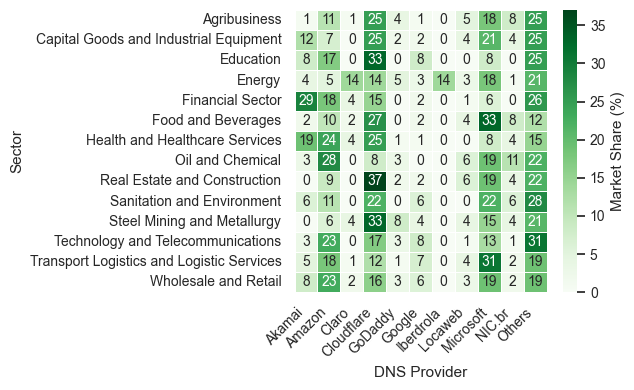

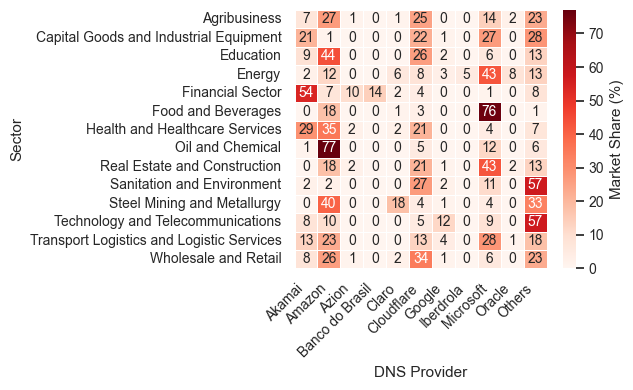

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Parâmetros padrão ABNT
textwidth_cm = 16     # largura do texto (ABNT) em cm
textwidth_inch = textwidth_cm / 2.54  # conversão para polegadas
fig_height = 5        # altura arbitrária, ajuste se necessário
font_size = 10        # tamanho padrão ABNT

PLOT_FONT_SIZE = font_size

pivot_pct_count = pd.read_csv('./tables/sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
pivot_pct_revenue = pd.read_csv('./tables/sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

# Padronização visual
sns.set(style="whitegrid")
plt.rcParams.update({
    "font.size": PLOT_FONT_SIZE,
    "axes.labelsize": PLOT_FONT_SIZE + 1,
    "axes.titlesize": PLOT_FONT_SIZE + 2,
    "xtick.labelsize": PLOT_FONT_SIZE,
    "ytick.labelsize": PLOT_FONT_SIZE,
})

# --------- Heatmap por Contagem de Domínios ---------
fig1, ax1 = plt.subplots(figsize=(textwidth_inch, fig_height))
hm1 = sns.heatmap(
    pivot_pct_count,
    annot=True,
    fmt='.0f',
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={'label': 'Market Share (%)'},
    ax=ax1
)
ax1.set_ylabel('Sector', fontsize=font_size + 1)
ax1.set_xlabel('DNS Provider', fontsize=font_size + 1)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=font_size)
ax1.set_yticklabels(ax1.get_yticklabels(), fontsize=font_size)
plt.tight_layout()
fig1.savefig(r'.\graphs\sector_provider_market_share_by_count_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# --------- Heatmap por Receita Agregada ---------
fig2, ax2 = plt.subplots(figsize=(textwidth_inch, fig_height))
hm2 = sns.heatmap(
    pivot_pct_revenue,
    annot=True,
    fmt='.0f',
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={'label': 'Market Share (%)'},
    ax=ax2
)
ax2.set_ylabel('Sector', fontsize=font_size + 1)
ax2.set_xlabel('DNS Provider', fontsize=font_size + 1)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=font_size)
ax2.set_yticklabels(ax2.get_yticklabels(), fontsize=font_size)
plt.tight_layout()
fig2.savefig(r'.\graphs\sector_provider_market_share_by_revenue_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()



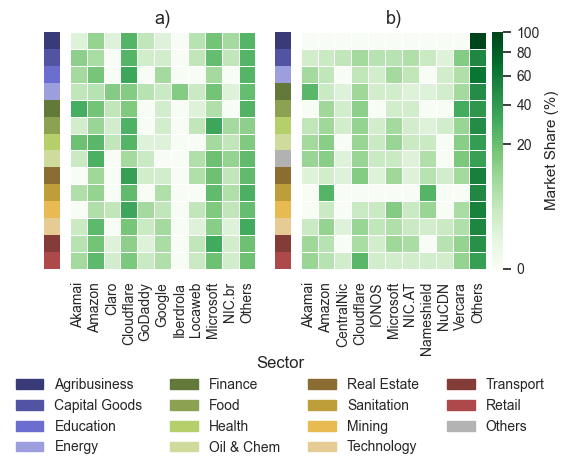

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.colors as mcolors  # NOVO

# Padrão ABNT
textwidth_cm = 16
textwidth_inch = textwidth_cm / 2.54
square_cm = 6
square_inch = square_cm / 2.54
font_size = 10

sector_display_names = {
    'Health and Healthcare Services': 'Health',
    'Financial Sector': 'Finance',
    'Energy': 'Energy',
    'Capital Goods and Industrial Equipment': 'Capital Goods',
    'Oil and Chemical': 'Oil & Chem',
    'Transport Logistics and Logistic Services': 'Transport',
    'Technology and Telecommunications': 'Technology',
    'Sanitation and Environment': 'Sanitation',
    'Real Estate and Construction': 'Real Estate',
    'Steel Mining and Metallurgy': 'Mining',
    'Food and Beverages': 'Food',
    'Agribusiness': 'Agribusiness',
    'Education': 'Education',
    'Wholesale and Retail': 'Retail',
    'Others': 'Others'
}

# Dados
br_count = pd.read_csv('./tables/sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
eu_count = pd.read_csv('./tables/eu_sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')

# Escala normal: já está em percentuais (0 a 100)
br_count_pct = br_count.copy()
eu_count_pct = eu_count.copy()

# Setores
all_sectors = list(br_count.index)
for sec in eu_count.index:
    if sec not in all_sectors:
        all_sectors.append(sec)
if 'Others' in all_sectors:
    all_sectors = [s for s in all_sectors if s != 'Others'] + ['Others']
elif 'Others' in br_count_pct.index or 'Others' in eu_count_pct.index:
    all_sectors.append('Others')

# Use tab20 para até 20 setores. Se precisar de mais, use tab20b/tab20c ou combine.
palette = sns.color_palette('tab20b', n_colors=len(all_sectors)-1)
sector_colors = {sector: palette[i % 20] for i, sector in enumerate(all_sectors) if sector != 'Others'}
sector_colors['Others'] = (0.7, 0.7, 0.7)

# Ajustar “Others” para ser a última coluna do EU sempre
eu_count_pct = eu_count_pct[[c for c in eu_count_pct.columns if c != 'Others'] + (['Others'] if 'Others' in eu_count_pct.columns else [])]

# Para barras laterais
row_display_names_br = [sector_display_names.get(sector, sector) for sector in br_count_pct.index]
row_display_names_eu = [sector_display_names.get(sector, sector) for sector in eu_count_pct.index]
row_colors_br = [sector_colors.get(sector, (0.7, 0.7, 0.7)) for sector in br_count_pct.index]
row_colors_eu = [sector_colors.get(sector, (0.7, 0.7, 0.7)) for sector in eu_count_pct.index]

# Layout horizontal
bar_width_cm = 0.4
bar_width_in = bar_width_cm / 2.54
gap_cm = 0.5  # Espaço entre áreas
gap_in = gap_cm / 2.54

# Altura um pouco maior por causa da legenda
fig_width = (2 * square_inch) + (2 * bar_width_in) + gap_in
fig_height = square_inch * 3

fig = plt.figure(figsize=(fig_width, fig_height))

# === NOVO: Normalização da escala de cor para dar mais contraste aos valores pequenos ===
gamma_value = 0.4  # Menor que 1 dá mais contraste para valores baixos
norm = mcolors.PowerNorm(gamma=gamma_value, vmin=0, vmax=100)

# --- Barra lateral Brasil ---
ax_bar_br = fig.add_axes([
    0.05, 0.3,
    bar_width_in/fig_width,
    square_inch/fig_height
])
ax_bar_br.imshow(
    np.arange(len(row_colors_br)).reshape(-1,1),
    cmap=plt.cm.colors.ListedColormap(row_colors_br),
    aspect='auto'
)
ax_bar_br.set_axis_off()

# --- Heatmap Brasil ---
ax_hm_br = fig.add_axes([
    ax_bar_br.get_position().x1 - 0.03,  # x0: imediatamente após a barra, com pequeno offset
    ax_bar_br.get_position().y0,
    square_inch/fig_width,
    square_inch/fig_height
])
sns.heatmap(
    br_count_pct,
    ax=ax_hm_br,
    cmap="Greens",         # troque para "magma" para melhor contraste visual
    annot=False,
    linewidths=0.4,
    cbar=False,
    yticklabels=False,
    xticklabels=True,
    square=True,
    norm=norm,            # <<< Aqui faz toda a diferença!
)
ax_hm_br.set_title('a)', fontsize=font_size + 3)
ax_hm_br.set_xlabel('')
ax_hm_br.set_ylabel('')
ax_hm_br.tick_params(axis='x', rotation=90, labelsize=font_size)
ax_hm_br.tick_params(axis='y', labelsize=font_size)

# --- Barra lateral Europa ---
ax_bar_eu = fig.add_axes([
    ax_hm_br.get_position().x1 + gap_in/fig_width-0.001,
    ax_bar_br.get_position().y0,
    bar_width_in/fig_width,
    square_inch/fig_height
])
ax_bar_eu.imshow(
    np.arange(len(row_colors_eu)).reshape(-1,1),
    cmap=plt.cm.colors.ListedColormap(row_colors_eu),
    aspect='auto'
)
ax_bar_eu.set_axis_off()

# --- Heatmap Europa ---
ax_hm_eu = fig.add_axes([
    ax_bar_eu.get_position().x1,
    ax_hm_br.get_position().y0,
    square_inch/fig_width,
    square_inch/fig_height
])
hm = sns.heatmap(
    eu_count_pct,
    ax=ax_hm_eu,
    cmap="Greens",
    annot=False,
    linewidths=0.4,
    cbar=True,
    yticklabels=False,
    xticklabels=True,
    square=True,
    norm=norm,            # <<< Mesmo ajuste
    cbar_kws={'shrink': 1, 'pad': 0.02}
)
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=font_size)
cbar.set_label('Market Share (%)', fontsize=font_size+1)
# Coloca a colorbar totalmente à direita
cbbox = ax_hm_eu.get_position()
cbar.ax.set_position([cbbox.x1 + 0.01, cbbox.y0, 0.025, cbbox.height])

ax_hm_eu.set_title('b)', fontsize=font_size + 3)
ax_hm_eu.set_xlabel('')
ax_hm_eu.set_ylabel('')
ax_hm_eu.tick_params(axis='x', rotation=90, labelsize=font_size)
ax_hm_eu.tick_params(axis='y', labelsize=font_size)

# --- Legenda abaixo, em 4 colunas ---
sector_legend = [
    Patch(color=sector_colors[sector], label=sector_display_names.get(sector, sector))
    for sector in all_sectors
]
fig.legend(
    handles=sector_legend,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.02),
    ncol=4,
    fontsize=font_size,
    title='Sector',
    title_fontsize=font_size + 2,
    frameon=False
)

plt.show()
fig.savefig(r'.\graphs\sector_provider_market_share_heatmap_br_eu_count.png', dpi=300, bbox_inches='tight')


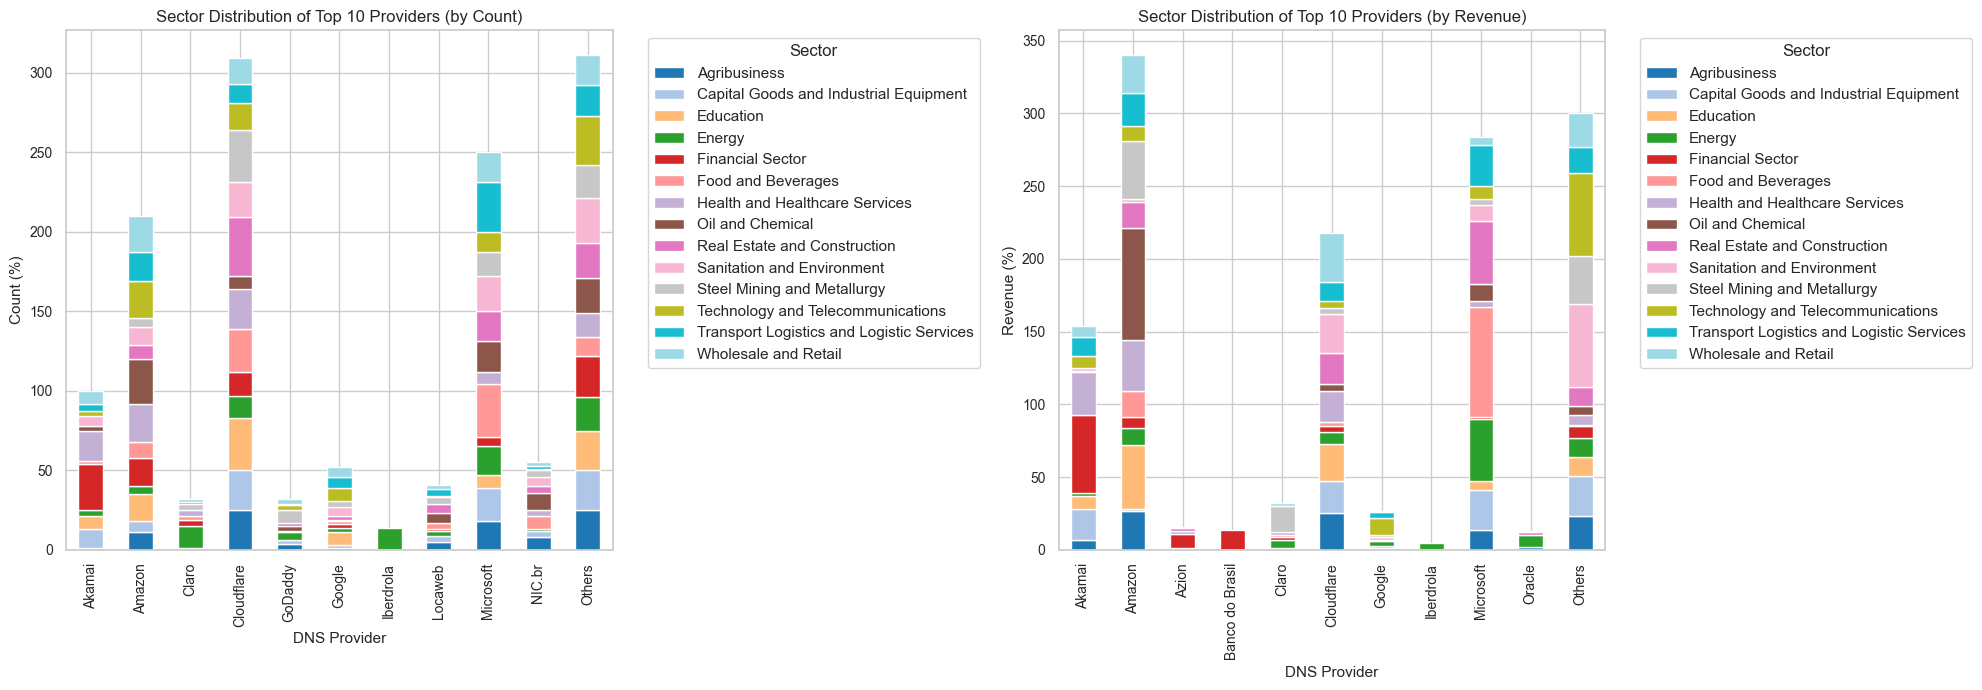

In [ ]:
# Load sector-provider pivot data from file before plotting
sector_provider_pivot = pd.read_csv('./tables/sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
sector_provider_pivot = pd.read_csv('./tables/sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# By Count
pivot_pct_count.T.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    colormap='tab20'
)
axes[0].set_title('Sector Distribution of Top 10 Providers (by Count)')
axes[0].set_xlabel('DNS Provider')
axes[0].set_ylabel('Count (%)')
axes[0].legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=90)

# By Revenue
pivot_pct_revenue.T.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    colormap='tab20'
)
axes[1].set_title('Sector Distribution of Top 10 Providers (by Revenue)')
axes[1].set_xlabel('DNS Provider')
axes[1].set_ylabel('Revenue (%)')
axes[1].legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

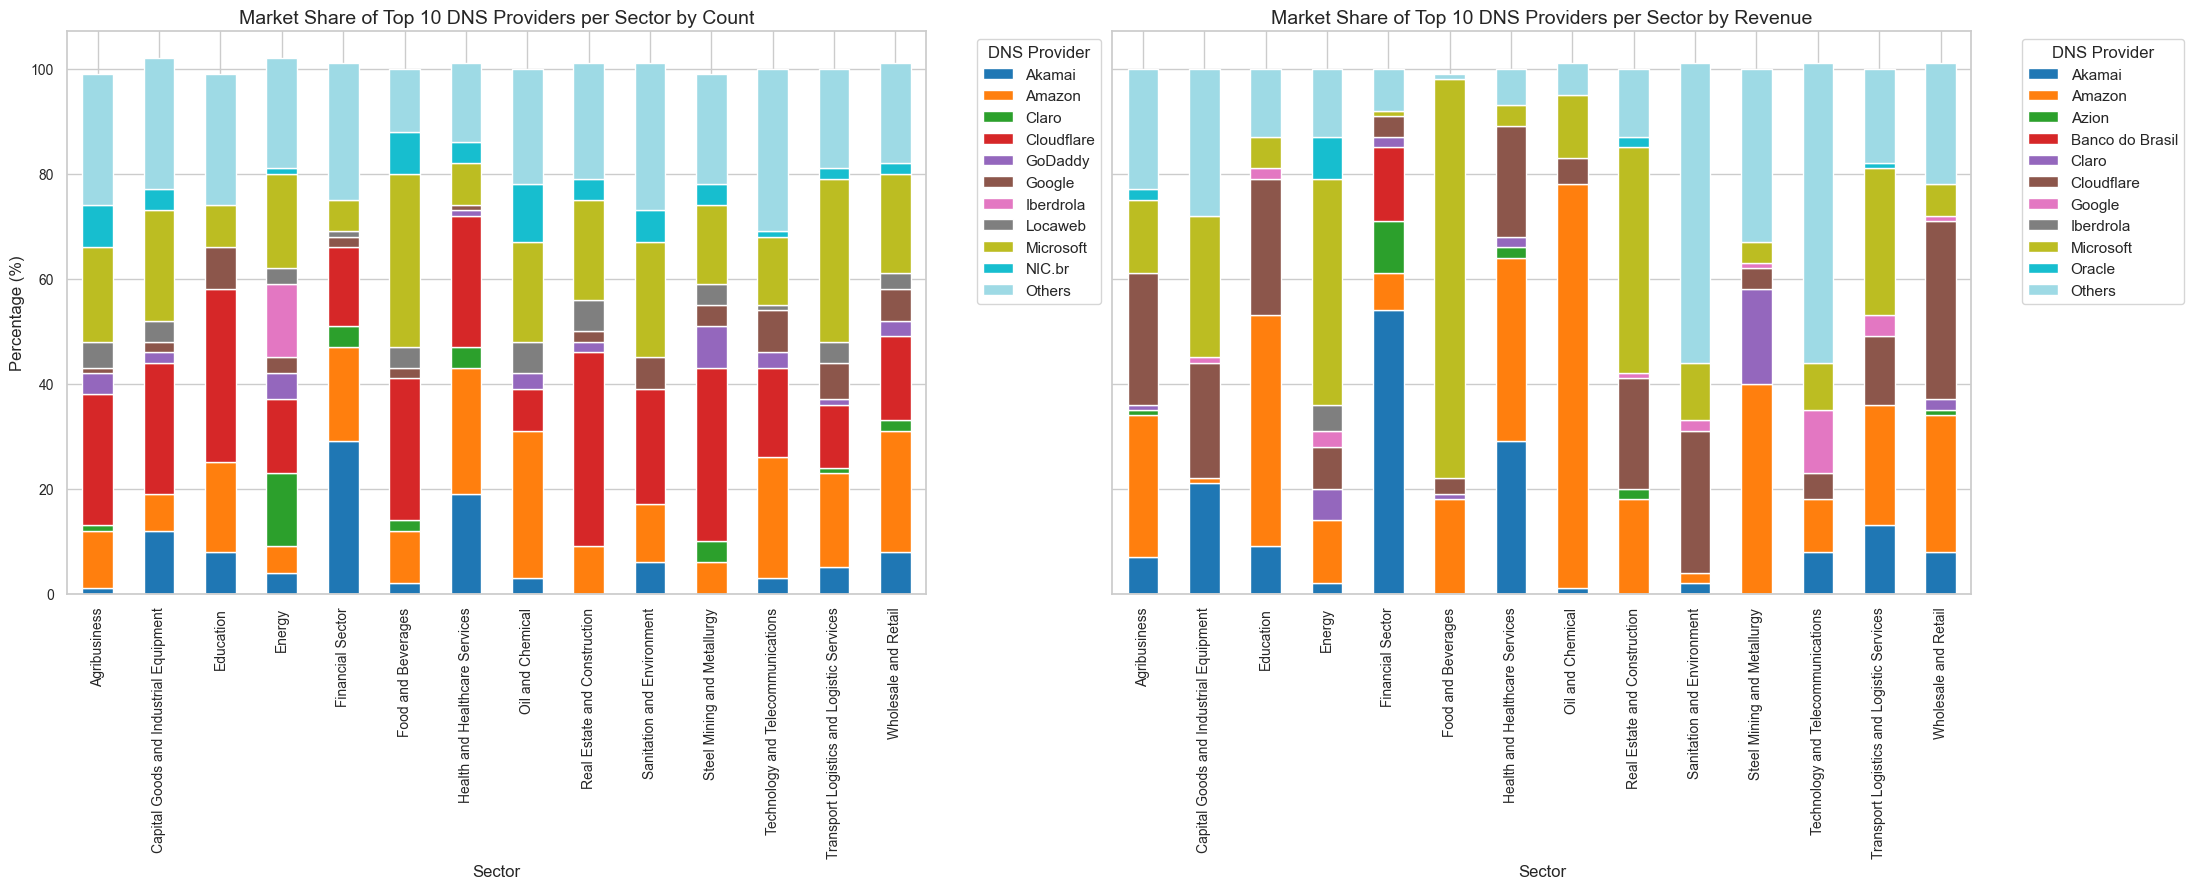

In [ ]:
import pandas as pd

# #### Market Share of Major DNS Providers per Sector (by Count and by Revenue)

# --- By Count ---
top_providers_count = base_data['dominant_provider'].value_counts().nlargest(10).index.tolist()
sector_provider_count = base_data.groupby(['sector_primary', 'dominant_provider']).size().reset_index(name='count')
sector_provider_count['provider_group'] = sector_provider_count['dominant_provider'].where(
    sector_provider_count['dominant_provider'].isin(top_providers_count), other='Others'
)
sector_provider_grouped_count = sector_provider_count.groupby(['sector_primary', 'provider_group'])['count'].sum().reset_index()
pivot_count = sector_provider_grouped_count.pivot(index='sector_primary', columns='provider_group', values='count').fillna(0)
pivot_pct_count = pivot_count.div(pivot_count.sum(axis=1), axis=0) * 100
pivot_pct_count = pivot_pct_count.round(0).reset_index().rename(columns={'sector_primary': 'Sector'}).set_index('Sector')
pivot_pct_count.to_csv(r'./tables/sector_provider_market_share_by_count.csv', sep=';', encoding='utf-8')

# --- By Revenue ---
top_providers_revenue = base_data.groupby('dominant_provider')['revenue'].sum().nlargest(10).index.tolist()
sector_provider_revenue = base_data.groupby(['sector_primary', 'dominant_provider'])['revenue'].sum().reset_index()
sector_provider_revenue['provider_group'] = sector_provider_revenue['dominant_provider'].where(
    sector_provider_revenue['dominant_provider'].isin(top_providers_revenue), other='Others'
)
sector_provider_grouped_revenue = sector_provider_revenue.groupby(['sector_primary', 'provider_group'])['revenue'].sum().reset_index()
pivot_revenue = sector_provider_grouped_revenue.pivot(index='sector_primary', columns='provider_group', values='revenue').fillna(0)
pivot_pct_revenue = pivot_revenue.div(pivot_revenue.sum(axis=1), axis=0) * 100
pivot_pct_revenue = pivot_pct_revenue.round(0).reset_index().rename(columns={'sector_primary': 'Sector'}).set_index('Sector')
pivot_pct_revenue.to_csv(r'./tables/sector_provider_market_share_by_revenue.csv', sep=';', encoding='utf-8')


# --- Load data from saved CSVs ---
import matplotlib.pyplot as plt

# Load percentage by count and by revenue
pivot_pct_count = pd.read_csv('./tables/sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
pivot_pct_revenue = pd.read_csv('./tables/sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

# --- Plot by Count and by Revenue side by side ---
fig, axes = plt.subplots(1, 2, figsize=(22, 9), sharey=True)

# Plot by Count
pivot_pct_count.plot(
    kind='bar',
    stacked=True,
    cmap='tab20',
    ax=axes[0]
)
axes[0].set_title('Market Share of Top 10 DNS Providers per Sector by Count', fontsize=14)
axes[0].set_xlabel('Sector', fontsize=12)
axes[0].set_ylabel('Percentage (%)', fontsize=12)
axes[0].legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=90)

# Plot by Revenue
pivot_pct_revenue.plot(
    kind='bar',
    stacked=True,
    cmap='tab20',
    ax=axes[1]
)
axes[1].set_title('Market Share of Top 10 DNS Providers per Sector by Revenue', fontsize=14)
axes[1].set_xlabel('Sector', fontsize=12)
axes[1].set_ylabel('')
axes[1].legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# Carregar o CSV original
df = base_data.copy()

# Agrupar receitas por setor e provedor dominante
grouped = df.groupby(['sector_primary', 'dominant_provider'])['revenue'].sum().reset_index()

# Função para obter top 10 por setor, marcando os demais como "Others"
def top10_and_others(group):
    # Ordena do maior para o menor
    group = group.sort_values(by='revenue', ascending=False)
    # Se tiver mais de 10 provedores, top 10 + soma do resto em "Others"
    if len(group) > 10:
        top = group.iloc[:10]
        others_sum = group.iloc[10:]['revenue'].sum()
        # Cria linha "Others"
        others_row = pd.DataFrame({
            'sector_primary': [group['sector_primary'].iloc[0]],
            'dominant_provider': ['Others'],
            'revenue': [others_sum]
        })
        result = pd.concat([top, others_row], ignore_index=True)
    else:
        result = group
    return result

# Aplicar a função para cada setor
result_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_and_others)

# Renomear as colunas para ficar igual ao exemplo desejado
result_df = result_df.rename(columns={
    'sector_primary': 'Sector',
    'dominant_provider': 'Provider',
    'revenue': 'Revenue'
})

# (Opcional) Ordenar resultado por setor, decrescentemente por receita
result_df = result_df.sort_values(['Sector', 'Revenue'], ascending=[True, False])

# Salvar em CSV
result_df.to_csv('./tables/top10_providers_by_sector_revenue.csv', sep=';', index=False)

print(result_df)



####################################################
df = base_data.copy()

# Agrupar por setor e provedor, contando domínios distintos
grouped = (
    df.groupby(['sector_primary', 'dominant_provider'])
    .size()
    .reset_index(name='domain_count')
)

# Função para obter top 10 por setor e agrupar os demais em "Others"
def top10_and_others_count(group):
    group = group.sort_values(by='domain_count', ascending=False)
    if len(group) > 10:
        top = group.iloc[:10]
        others_sum = group.iloc[10:]['domain_count'].sum()
        others_row = pd.DataFrame({
            'sector_primary': [group['sector_primary'].iloc[0]],
            'dominant_provider': ['Others'],
            'domain_count': [others_sum]
        })
        result = pd.concat([top, others_row], ignore_index=True)
    else:
        result = group
    return result

# Aplicar função para cada setor
result_count_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_and_others_count)

# Renomear colunas para o formato desejado
result_count_df = result_count_df.rename(columns={
    'sector_primary': 'Sector',
    'dominant_provider': 'Provider',
    'domain_count': 'Count'
})

# Ordenar resultado
result_count_df = result_count_df.sort_values(['Sector', 'Count'], ascending=[True, False])

# Salvar resultado
result_count_df.to_csv('./tables/top10_providers_by_sector_count.csv', sep=';', index=False)

print(result_count_df)

print(result_df)

                  Sector    Provider      Revenue
0           Agribusiness      Amazon  166535182.0
1           Agribusiness  Cloudflare  157497831.0
2           Agribusiness   Microsoft   88835551.0
10          Agribusiness      Others   50289265.0
3           Agribusiness      Akamai   44588674.0
..                   ...         ...          ...
5   Wholesale and Retail     GoDaddy   20359824.0
6   Wholesale and Retail      NIC.br   16346982.0
7   Wholesale and Retail  Telefônica   13647849.0
8   Wholesale and Retail       Claro    9981865.0
9   Wholesale and Retail         ANX    6719317.0

[151 rows x 3 columns]
                  Sector        Provider  Count
0           Agribusiness      Cloudflare     19
1           Agribusiness       Microsoft     14
10          Agribusiness          Others     13
2           Agribusiness          Amazon      8
3           Agribusiness          NIC.br      6
..                   ...             ...    ...
5   Wholesale and Retail         Locaweb

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_15284\3151393994.py:29: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_and_others)
C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_15284\3151393994.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result_count_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_

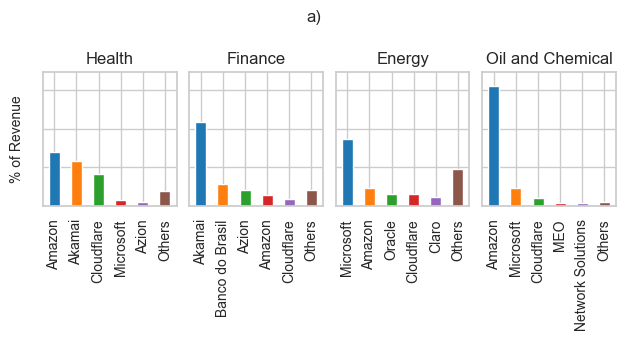

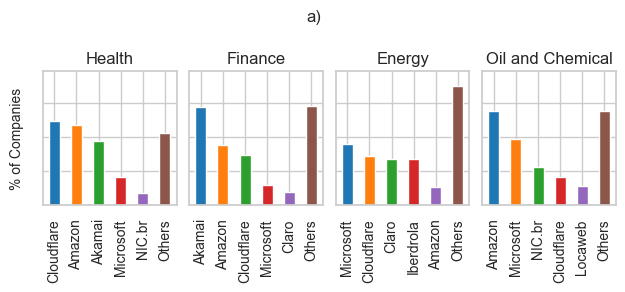

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

desired_sectors = [
    'Health and Healthcare Services',
    'Financial Sector',
    'Energy',
    'Oil and Chemical'
]

# Nomes para mostrar nos gráficos:
display_names = [
    'Health',
    'Finance',
    'Energy',
    'Oil and Chemical'
]

# Parâmetro padrão ABNT
textwidth_cm = 16
textwidth_inch = textwidth_cm / 2.54
font_size = 10

n_plots = len(desired_sectors)
square_size = textwidth_inch / n_plots
hspace = 0.15
fig_width = textwidth_inch
fig_height = square_size + 1.5

# --------- Revenue ----------
df = pd.read_csv('./tables/top10_providers_by_sector_revenue.csv', sep=';')
df = df[df['Sector'].isin(desired_sectors) & (df['Sector'] != 'Total')].copy()
df['TotalRevenue'] = df.groupby('Sector')['Revenue'].transform('sum')
df['Pct'] = df['Revenue'] / df['TotalRevenue'] * 100
df_top5 = df[df['Provider'] != 'Others'].copy()
df_top5['Rank'] = df_top5.groupby('Sector')['Revenue'].rank(method='first', ascending=False)
df_top5 = df_top5[df_top5['Rank'] <= 5]

plot_df = []
for sector in desired_sectors:
    sector_df = df[df['Sector'] == sector].copy()
    sector_top5 = df_top5[df_top5['Sector'] == sector].sort_values('Pct', ascending=False)
    providers = list(sector_top5['Provider'])
    pct_values = list(sector_top5['Pct'])
    while len(providers) < 5:
        providers.append('(empty)')
        pct_values.append(0)
    top5_names = set(sector_top5['Provider'])
    others_pct = sector_df[~sector_df['Provider'].isin(top5_names)]['Pct'].sum()
    providers.append('Others')
    pct_values.append(others_pct)
    plot_df.append((providers, pct_values))

ymax = max([max(pct_values) for providers, pct_values in plot_df])
ymax = min(100, ymax * 1.12)

fig, axes = plt.subplots(1, n_plots, figsize=(fig_width, fig_height), sharey=True)
if n_plots == 1:
    axes = [axes]

for i, (ax, (providers, pct_values)) in enumerate(zip(axes, plot_df)):
    bars = ax.bar(providers, pct_values, color=plt.cm.tab10.colors[:6], width=0.5)
    ax.set_title(display_names[i], fontsize=font_size + 2)  # <-- Título correto
    if i == 0:
        ax.set_ylabel("% of Revenue", fontsize=font_size)
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
    ax.set_ylim(0, ymax)
    ax.tick_params(axis='x', rotation=90, labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_box_aspect(1)
    ax.set_xlabel("")


fig.suptitle('a)', fontsize=font_size+2, y=0.95)
plt.subplots_adjust(left=0.07, right=0.98, top=0.84, bottom=0.22, wspace=hspace/square_size)
plt.show()
fig.savefig(r'.\graphs\br_top5_providers_by_sector_by_revenue.png', dpi=300, bbox_inches='tight')

# --------- Repita igual para o Count ---------
df_count = pd.read_csv('./tables/top10_providers_by_sector_count.csv', sep=';')
df_count = df_count[df_count['Sector'].isin(desired_sectors) & (df_count['Sector'] != 'Total')].copy()
count_col = 'Count' if 'Count' in df_count.columns else 'DomainCount'
df_count['Total'] = df_count.groupby('Sector')[count_col].transform('sum')
df_count['Pct'] = df_count[count_col] / df_count['Total'] * 100
df_count_top5 = df_count[df_count['Provider'] != 'Others'].copy()
df_count_top5['Rank'] = df_count_top5.groupby('Sector')[count_col].rank(method='first', ascending=False)
df_count_top5 = df_count_top5[df_count_top5['Rank'] <= 5]

plot_df_count = []
for sector in desired_sectors:
    sector_df = df_count[df_count['Sector'] == sector].copy()
    sector_top5 = df_count_top5[df_count_top5['Sector'] == sector].sort_values('Pct', ascending=False)
    providers = list(sector_top5['Provider'])
    pct_values = list(sector_top5['Pct'])
    while len(providers) < 5:
        providers.append('(empty)')
        pct_values.append(0)
    top5_names = set(sector_top5['Provider'])
    others_pct = sector_df[~sector_df['Provider'].isin(top5_names)]['Pct'].sum()
    providers.append('Others')
    pct_values.append(others_pct)
    plot_df_count.append((providers, pct_values))

ymax = max([max(pct_values) for providers, pct_values in plot_df_count])
ymax = min(100, ymax * 1.12)

fig, axes = plt.subplots(1, n_plots, figsize=(fig_width, fig_height), sharey=True)
if n_plots == 1:
    axes = [axes]

for i, (ax, (providers, pct_values)) in enumerate(zip(axes, plot_df_count)):
    bars = ax.bar(providers, pct_values, color=plt.cm.tab10.colors[:6], width=0.5)
    ax.set_title(display_names[i], fontsize=font_size + 2)  # <-- Título correto
    if i == 0:
        ax.set_ylabel("% of Companies", fontsize=font_size)
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
    ax.set_ylim(0, ymax)
    ax.tick_params(axis='x', rotation=90, labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_box_aspect(1)
    ax.set_xlabel("")

fig.suptitle('a)', fontsize=font_size+2, y=0.95)
plt.subplots_adjust(left=0.07, right=0.98, top=0.84, bottom=0.22, wspace=hspace/square_size)
plt.show()
fig.savefig(r'.\graphs\br_top5_providers_by_sector_by_count.png', dpi=300, bbox_inches='tight')


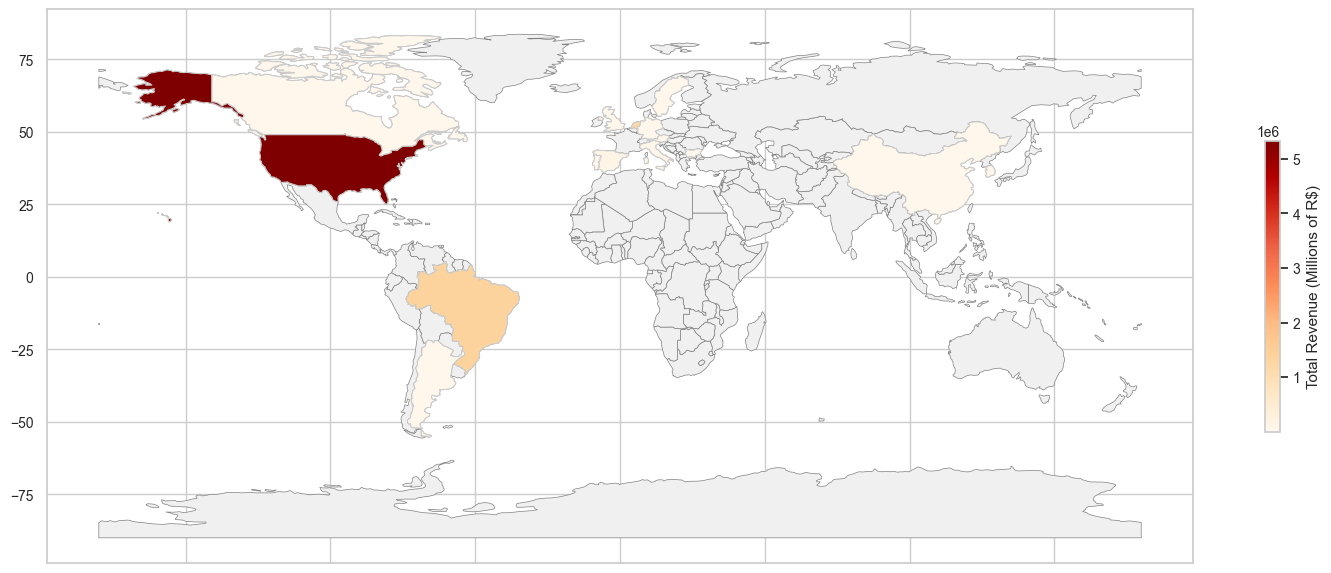

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_15284\3491903203.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


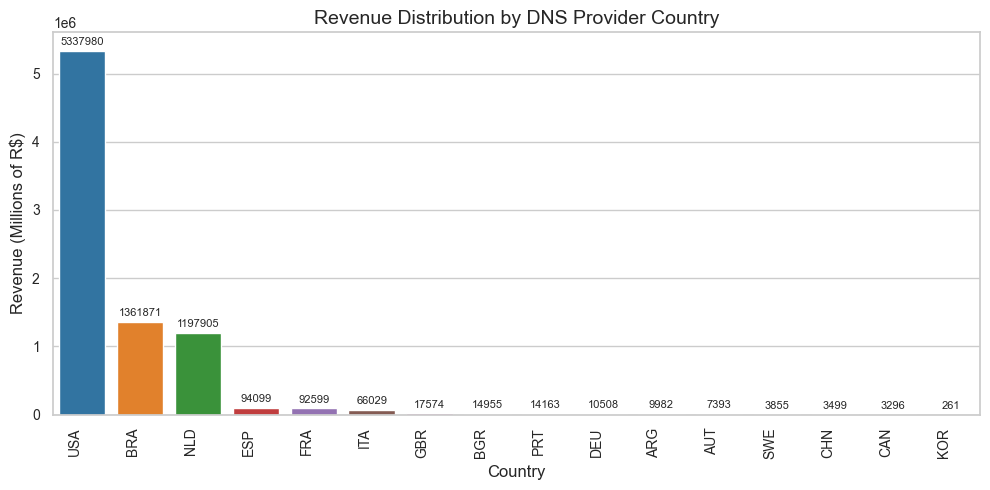

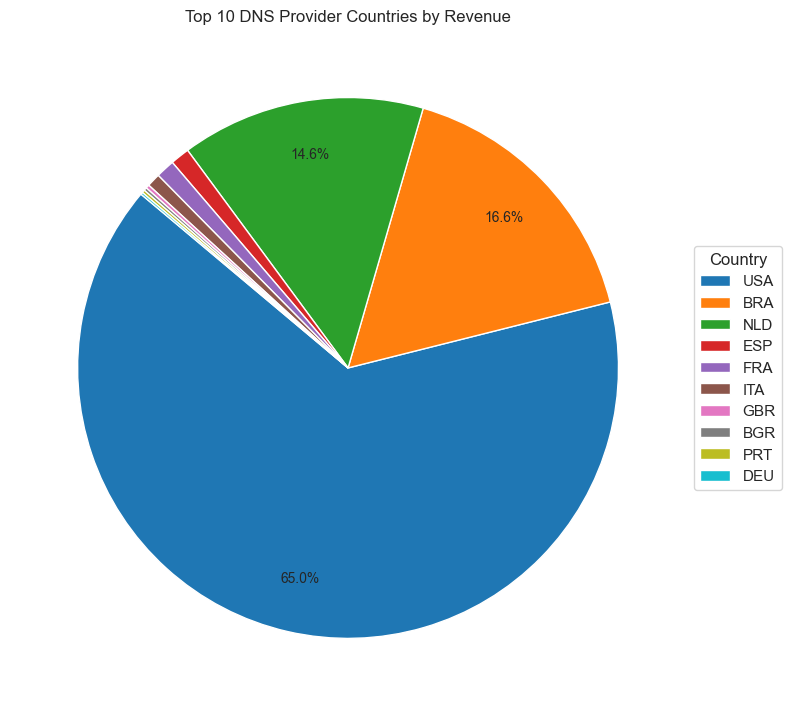

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

def iso2_to_iso3(iso2_code):
    try:
        return pycountry.countries.get(alpha_2=iso2_code).alpha_3
    except:
        return None

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)
df['revenue'] = df['revenue'] / 1_000  # Convert revenue to millions of R$
revenue_by_country = df.groupby('dominant_provider_country')['revenue'].sum().reset_index()

revenue_by_country = revenue_by_country.rename(columns={
    'dominant_provider_country': 'Country',
    'revenue': 'Revenue (Millions of R$)'
})
revenue_by_country = revenue_by_country.set_index('Country')
revenue_by_country.to_csv('./tables/dominant_country_provider_distribution_by_revenue.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_revenue = world.merge(
    revenue_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Save ready-to-plot data
world_revenue.to_csv('./tables/world_revenue_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

# Plot choropleth
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_revenue.plot(
    ax=ax,
    column='Revenue (Millions of R$)',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Total Revenue (Millions of R$)", 'shrink': 0.3}
)
ax.set_xticklabels([])
plt.tight_layout()
plt.show()

fig.savefig(r'.\graphs\br_geographical_origin_of_dns_providers_revenue_map.png', dpi=300, bbox_inches='tight')

# Barplot
revenue_sorted = revenue_by_country.sort_values(by='Revenue (Millions of R$)', ascending=False).reset_index()
revenue_sorted.to_csv('./tables/revenue_sorted_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=revenue_sorted,
    x='Country',
    y='Revenue (Millions of R$)',
    palette='tab10'
)

for index, row in revenue_sorted.iterrows():
    plt.text(
        index, 
        row['Revenue (Millions of R$)'] + max(revenue_sorted['Revenue (Millions of R$)']) * 0.01, 
        f"{row['Revenue (Millions of R$)']:.0f}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Revenue Distribution by DNS Provider Country', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Revenue (Millions of R$)', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# pieplot

def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

revenue_top = revenue_sorted.head(10)
revenue_top.to_csv('./tables/revenue_top_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    revenue_top['Revenue (Millions of R$)'],
    autopct=autopct_format,
    startangle=140,
    colors=sns.color_palette('tab10', n_colors=len(revenue_top)),
    pctdistance=0.8,
    labeldistance=1.1
)

plt.title('Top 10 DNS Provider Countries by Revenue')
plt.legend(wedges, revenue_top['Country'], title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


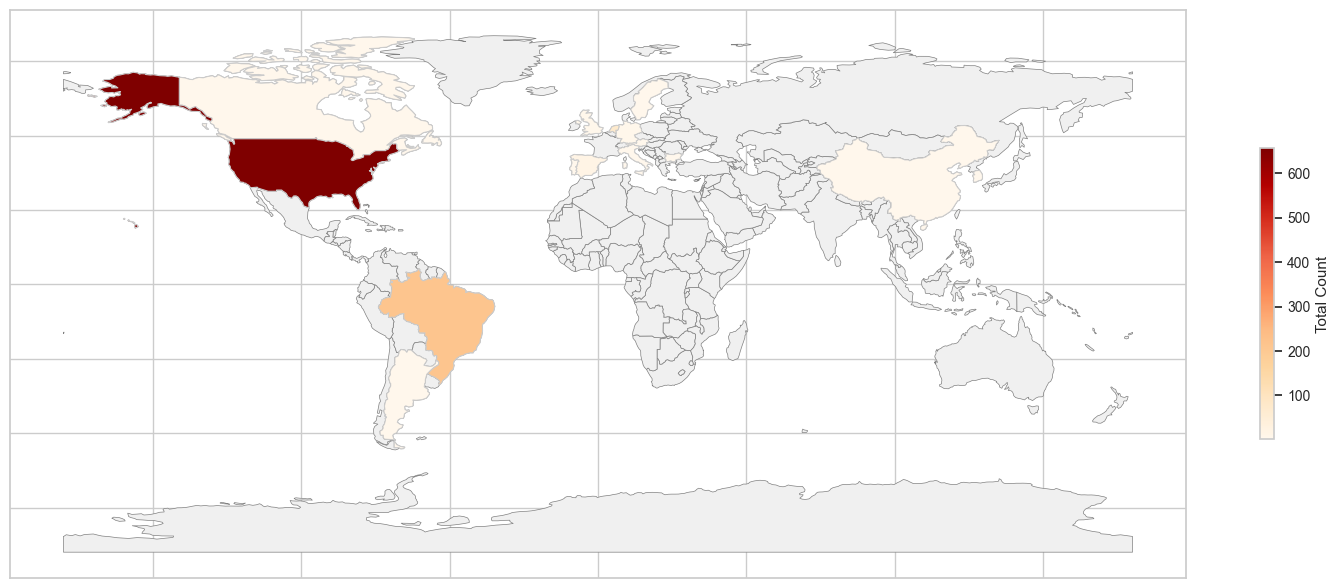

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_15284\1845695000.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


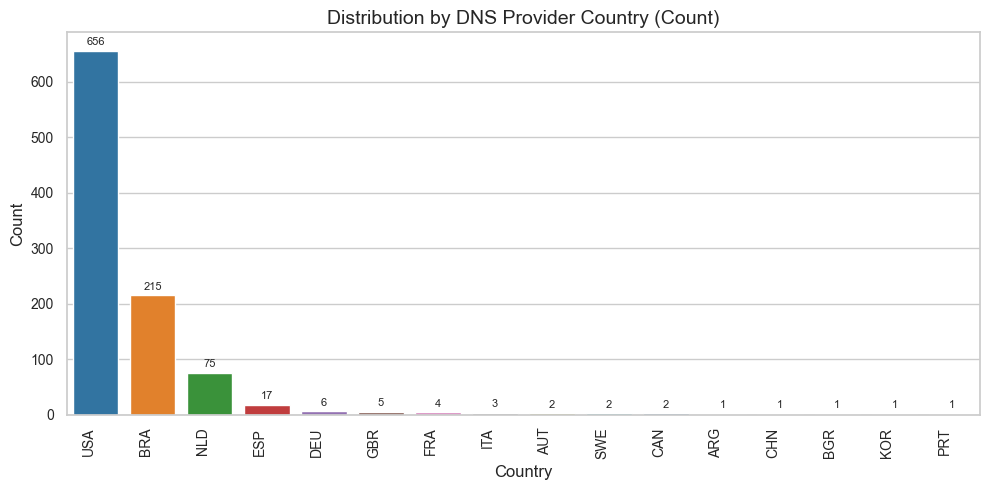

In [ ]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)

# Agrupar por país e contar o número de empresas por país do provedor dominante
count_by_country = df.groupby('dominant_provider_country').size().reset_index(name='Count')

count_by_country = count_by_country.rename(columns={
    'dominant_provider_country': 'Country'
})
count_by_country = count_by_country.set_index('Country')
count_by_country.to_csv('./tables/br_dominant_country_provider_distribution_by_count.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_count = world.merge(
    count_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Plot choropleth
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_count.plot(
    ax=ax,
    column='Count',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Total Count", 'shrink': 0.3}
)
ax.set_xticklabels([])
ax.set_yticklabels([])
plt.tight_layout()
plt.show()

fig.savefig(r'.\graphs\br_geographical_origin_of_dns_providers_count_map.png', dpi=300, bbox_inches='tight')

# Barplot
count_sorted = count_by_country.sort_values(by='Count', ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=count_sorted,
    x='Country',
    y='Count',
    palette='tab10'
)

for index, row in count_sorted.iterrows():
    plt.text(
        index, 
        row['Count'] + max(count_sorted['Count']) * 0.01, 
        f"{int(row['Count'])}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Distribution by DNS Provider Country (Count)', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()



C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_15284\2562089606.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


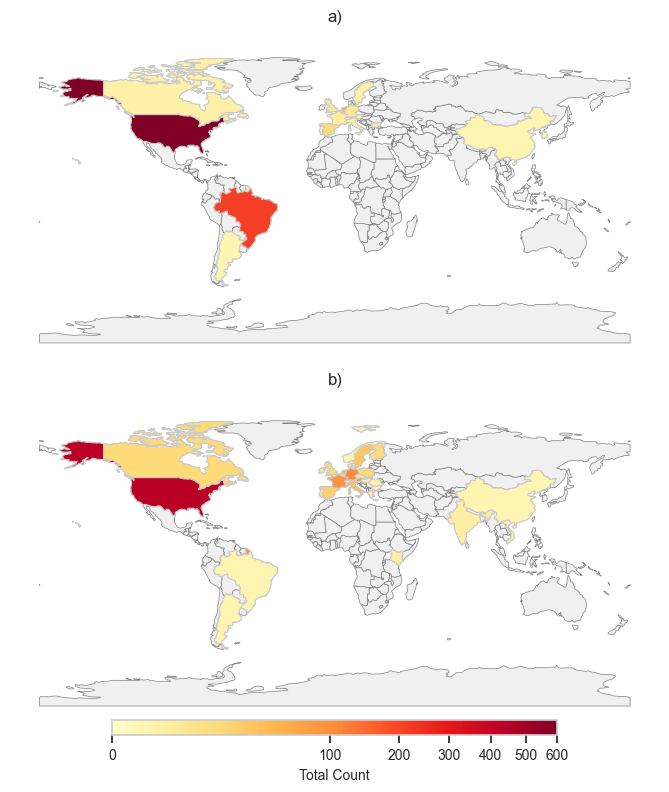

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import matplotlib.colors as mcolors

# Padrão ABNT (16cm de largura)
textwidth_cm = 16
textwidth_inch = (textwidth_cm / 2.54)*(1/0.85)  # ≈ 6.3 pol

font_size = 10  # Aproximação de \normalsize LaTeX ABNT

def iso2_to_iso3(iso2_code):
    try:
        if pd.isnull(iso2_code):
            return None
        return pycountry.countries.get(alpha_2=iso2_code.upper()).alpha_3
    except:
        return None

# Dados Brasil
df_br = base_data.copy()
df_br['dominant_provider_country'] = df_br['dominant_provider_country'].apply(iso2_to_iso3)
df_br['dominant_provider_country'] = df_br['dominant_provider_country'].str.upper()
count_by_country_br = df_br.groupby('dominant_provider_country').size().reset_index(name='Count')
count_by_country_br = count_by_country_br.rename(columns={'dominant_provider_country': 'Country'})
count_by_country_br = count_by_country_br.set_index('Country')

# Dados EU
eu_base_data = pd.read_csv(r'..\src\eu_analysis_data.csv', sep=';', encoding='utf-8')
df_eu = eu_base_data.copy()
df_eu['dominant_provider_country'] = df_eu['dominant_provider_country'].apply(iso2_to_iso3)
df_eu['dominant_provider_country'] = df_eu['dominant_provider_country'].str.upper()
count_by_country_eu = df_eu.groupby('dominant_provider_country').size().reset_index(name='Count')
count_by_country_eu = count_by_country_eu.rename(columns={'dominant_provider_country': 'Country'})
count_by_country_eu = count_by_country_eu.set_index('Country')

# Shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_count_br = world.merge(count_by_country_br.reset_index(), how='left', left_on='ADM0_A3', right_on='Country')
world_count_eu = world.merge(count_by_country_eu.reset_index(), how='left', left_on='ADM0_A3', right_on='Country')

# Colormap e escala não-linear para destacar valores baixos
cmap = 'YlOrRd'
norm = mcolors.PowerNorm(gamma=0.4, vmin=0, vmax=600)

# --- Plot padrão ABNT ---
# Altura definida para proporção confortável; ajuste se quiser mapas mais ou menos "altos"
fig_height = textwidth_inch * 1

fig, axes = plt.subplots(
    2, 1,
    figsize=(textwidth_inch, fig_height),
    constrained_layout=False
)
plt.subplots_adjust(hspace=0.15)

for ax in axes:
    world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5, zorder=1)
    ax.set_aspect('equal')

# Brasil
world_count_br.plot(
    ax=axes[0],
    column='Count',
    cmap=cmap,
    linewidth=0.8,
    edgecolor='0.8',
    legend=False,
    norm=norm,
    zorder=2
)
axes[0].set_title('a)', fontsize=font_size+2, pad=16)
axes[0].axis('off')

# Europa
world_count_eu.plot(
    ax=axes[1],
    column='Count',
    cmap=cmap,
    linewidth=0.8,
    edgecolor='0.8',
    legend=False,
    norm=norm,
    zorder=2
)
axes[1].set_title('b)', fontsize=font_size+2, pad=16)
axes[1].axis('off')

# Colorbar manual compartilhada
fig.subplots_adjust(bottom=0.16)
cax = fig.add_axes([0.2, 0.00, 0.6, 0.02])  # [left, bottom, width, height]
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
cbar.set_label("Total Count", fontsize=font_size)
cbar.ax.tick_params(labelsize=font_size)

plt.tight_layout()
plt.show()
fig.savefig(r'.\graphs\br_eu_geographical_origin_of_dns_providers_count_map.png', dpi=300, bbox_inches='tight')


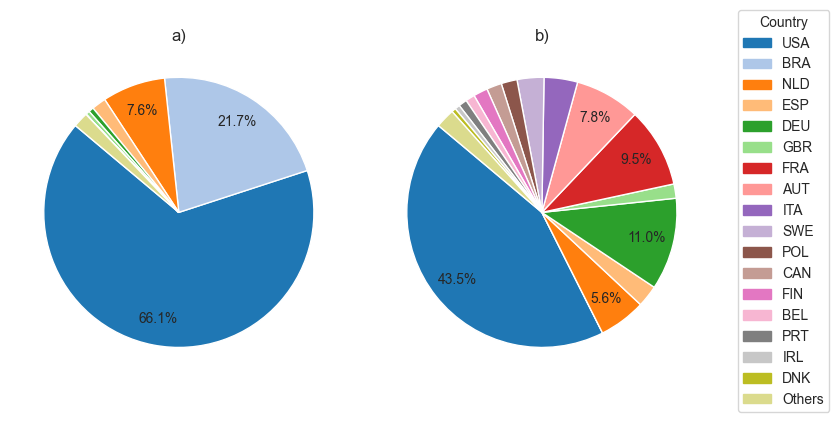

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Parâmetros do padrão ABNT
textwidth_cm = 16
textwidth_inch = (textwidth_cm / 2.54)*(1/0.85)  # ≈ 6.3 pol
font_size = 10   # Aproximação do padrão LaTeX/ABNT \normalsize

def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

def process_pie_data(df):
    total = df['Count'].sum()
    df['Pct'] = df['Count'] / total * 100
    df['Country'] = df['Country'].where(df['Pct'] >= 0.5, 'Others')
    df = df.groupby('Country', as_index=False)['Count'].sum()
    df = df.sort_values(by='Count', ascending=False)
    # Garante que 'Others' esteja por último
    if 'Others' in df['Country'].values:
        others_row = df[df['Country'] == 'Others']
        df = df[df['Country'] != 'Others']
        df = pd.concat([df, others_row], ignore_index=True)
    return df

# --- Dados Brasil ---
count_by_country_br = pd.read_csv('./tables/br_dominant_country_provider_distribution_by_count.csv', sep=';', encoding='utf-8')
count_sorted_br = process_pie_data(count_by_country_br)

# --- Dados União Europeia ---
count_by_country_eu = pd.read_csv('./tables/eu_dominant_country_provider_distribution_by_count.csv', sep=';', encoding='utf-8')
count_sorted_eu = process_pie_data(count_by_country_eu)

# ----- Lista de países única, mantendo 'Others' no final -----
countries_all = list(count_sorted_br['Country']) + [c for c in count_sorted_eu['Country'] if c not in list(count_sorted_br['Country'])]
if 'Others' in countries_all:
    countries_all = [c for c in countries_all if c != 'Others'] + ['Others']

# Paleta de cores fixa, pode ser tab20 ou personalizada
color_palette = sns.color_palette('tab20', n_colors=len(countries_all))
country_colors = {country: color_palette[i] for i, country in enumerate(countries_all)}

# ----- Ajustar valores para cada gráfico na mesma ordem de país -----
def get_counts_for_pie(df, countries):
    country_to_count = dict(zip(df['Country'], df['Count']))
    return [country_to_count.get(c, 0) for c in countries]

counts_br = get_counts_for_pie(count_sorted_br, countries_all)
counts_eu = get_counts_for_pie(count_sorted_eu, countries_all)
colors = [country_colors[c] for c in countries_all]

# ----------- Plot -----------
fig, axes = plt.subplots(1, 2, figsize=(textwidth_inch, textwidth_inch / 2))

# Brasil (esquerda)
wedges_br, texts_br, autotexts_br = axes[0].pie(
    counts_br,
    autopct=autopct_format,
    startangle=140,
    colors=colors,
    pctdistance=0.8,
    labeldistance=1.1
)
axes[0].set_title('a)', fontsize=font_size+2, pad=1)
plt.setp(texts_br, fontsize=font_size)
plt.setp(autotexts_br, fontsize=font_size)

# União Europeia (direita)
wedges_eu, texts_eu, autotexts_eu = axes[1].pie(
    counts_eu,
    autopct=autopct_format,
    startangle=140,
    colors=colors,
    pctdistance=0.8,
    labeldistance=1.1
)
axes[1].set_title('b)', fontsize=font_size+2, pad=1)
plt.setp(texts_eu, fontsize=font_size)
plt.setp(autotexts_eu, fontsize=font_size)

# Legenda única à direita
wedges_legend = [plt.matplotlib.patches.Patch(color=country_colors[c], label=c) for c in countries_all]
fig.legend(
    handles=wedges_legend,
    title="Country",
    title_fontsize=font_size,
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=font_size
)

plt.tight_layout()
plt.show()
fig.savefig(r'.\graphs\top_dns_provider_countries_by_count_pie_br_eu.png', dpi=300, bbox_inches='tight')
